Dataset shape: (660, 7)
   Sl_No  Customer Key  Avg_Credit_Limit  Total_Credit_Cards  \
0      1         87073            100000                   2   
1      2         38414             50000                   3   
2      3         17341             50000                   7   
3      4         40496             30000                   5   
4      5         47437            100000                   6   

   Total_visits_bank  Total_visits_online  Total_calls_made  
0                  1                    1                 0  
1                  0                   10                 9  
2                  1                    3                 4  
3                  1                    1                 4  
4                  0                   12                 3  

Data normalization completed!


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_8 (Dense)                 │ (None, 16)             │            96 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 16)             │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 5)              │            85 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 461 (1.80 KB)

 Trainable params: 461 (1.80 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 1.0693 - val_loss: 0.9823
Epoch 2/50
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.9965 - val_loss: 0.9307
Epoch 3/50
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.9481 - val_loss: 0.8864
Epoch 4/50
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.9014 - val_loss: 0.8335
Epoch 5/50
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.8488 - val_loss: 0.7725
Epoch 6/50
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.7884 - val_loss: 0.7044
Epoch 7/50
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.7244 - val_loss: 0.6389
Epoch 8/50
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.6636 - val_loss: 0.5854
Epoch 9/50
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.6060 - val_loss: 0.5359
Epoch 10/50
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.5460 - val_loss: 0.4905
Epoch 11/50
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.4902 - val_loss: 0.4506
Epoch 12/50
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.4443 - val_l

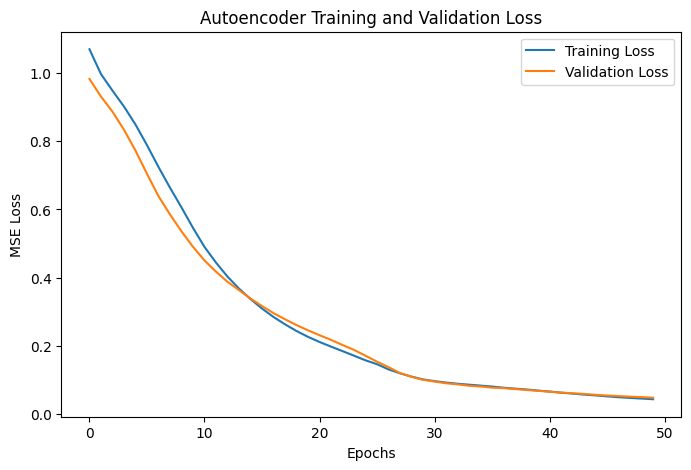

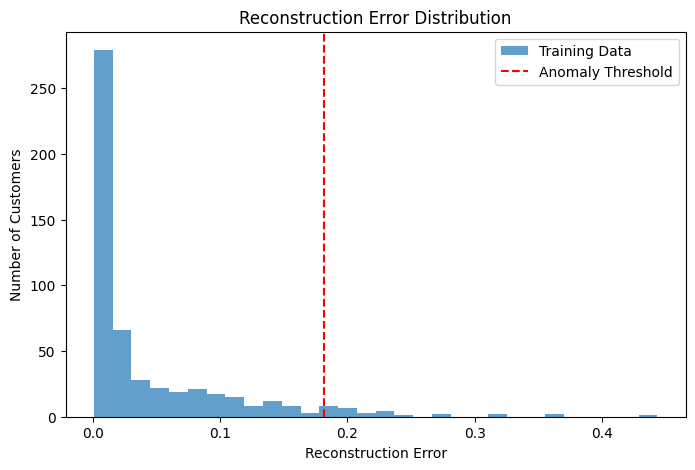

In [4]:

# STEP 1: Import required libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# STEP 2: Load the credit card dataset

data = pd.read_csv("/content/Credit Card Customer Data - Credit Card Customer Data.csv")

print("Dataset shape:", data.shape)
print(data.head())

# STEP 3: Separate features (dropping ID columns, and since there is no 'Class' column, we use unsupervised learning)

X = data.drop(["Sl_No", "Customer Key"], axis=1)

# STEP 4: Split the dataset into training and testing data

X_train, X_test = train_test_split(
    X, test_size=0.2, random_state=42
)

# STEP 5: Normalize the features

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("\nData normalization completed!")

# STEP 6: Define the autoencoder

input_dim = X_train.shape[1]

autoencoder = keras.Sequential([
    keras.Input(shape=(input_dim,)),

    # Encoder
    layers.Dense(16, activation="relu"),
    layers.Dense(8, activation="relu"),

    # Decoder
    layers.Dense(16, activation="relu"),
    layers.Dense(input_dim, activation="linear")
])

# STEP 7: Compile the model

autoencoder.compile(
    optimizer="adam",
    loss="mse"
)

# STEP 8: Display model summary

autoencoder.summary()

# STEP 9: Train the autoencoder on the features

history = autoencoder.fit(
    X_train,
    X_train,
    epochs=50,
    batch_size=32,
    shuffle=True,
    validation_split=0.2,
    verbose=1
)

# STEP 10: Calculate reconstruction error on training data

train_predictions = autoencoder.predict(X_train)

train_errors = np.mean(
    np.square(X_train - train_predictions), axis=1
)

# STEP 11: Set the anomaly detection threshold (top 5% highest errors)

threshold = np.percentile(train_errors, 95)

print("\nAnomaly Threshold:", threshold)

# STEP 12: Reconstruct the test transactions

test_predictions = autoencoder.predict(X_test)

# STEP 13: Calculate reconstruction error for test data

test_errors = np.mean(
    np.square(X_test - test_predictions), axis=1
)

# STEP 14: Detect anomalies (outliers with unusually high reconstruction error)

y_pred = (test_errors > threshold).astype(int)

print("\nPredicted Normal Customers (Test):", np.sum(y_pred == 0))
print("Predicted Anomalous Customers (Test):", np.sum(y_pred == 1))

# STEP 15: Display training and validation loss

plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Autoencoder Training and Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("MSE Loss")
plt.legend()
plt.show()

# STEP 16: Display reconstruction error distribution

plt.figure(figsize=(8, 5))

plt.hist(train_errors, bins=30, alpha=0.7, label="Training Data")
plt.axvline(threshold, color='r', linestyle="--", label="Anomaly Threshold")

plt.title("Reconstruction Error Distribution")
plt.xlabel("Reconstruction Error")
plt.ylabel("Number of Customers")
plt.legend()
plt.show()
